In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")

print("Dispositivo:", device)

Dispositivo: cuda


In [3]:
iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
class_names = iris.target_names

print("Dimensão dos dados:", X.shape)
print("Classes:", class_names)
print("Atributos:", feature_names)

Dimensão dos dados: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']
Atributos: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [4]:
df = pd.DataFrame(X, columns=feature_names)
df["species"] = [class_names[i] for i in y]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
X_train, X_val = train_test_split(
    X,
    test_size=0.2,
    random_state=SEED,
    shuffle=True
)

print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)

Treinamento: (120, 4)
Validação: (30, 4)


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

In [7]:
X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
)

print("Treinamento:", X_train_tensor.shape)
print("Validação:", X_val_tensor.shape)

Treinamento: torch.Size([120, 4])
Validação: torch.Size([30, 4])


In [8]:
BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_tensor)
val_dataset = TensorDataset(X_val_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [9]:
class Encoder(nn.Module):

    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()

        # Camada compartilhada
        self.hidden = nn.Linear(input_dim, hidden_dim)

        # Camadas responsáveis pelos parâmetros da distribuição
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

        self.relu = nn.ReLU()

    def forward(self, x):

        h = self.relu(self.hidden(x))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

In [10]:
def reparameterize(mu, logvar):

    # Recuperando o desvio padrão
    std = torch.exp(0.5 * logvar)

    # Amostrando ruído de uma normal padrão
    epsilon = torch.randn_like(std)

    # Construindo a amostra latente
    z = mu + std * epsilon

    return z

In [11]:
class Decoder(nn.Module):

    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()

        self.hidden = nn.Linear(latent_dim, hidden_dim)
        self.output = nn.Linear(hidden_dim, output_dim)

        self.relu = nn.ReLU()

    def forward(self, z):

        h = self.relu(self.hidden(z))

        reconstruction = self.output(h)

        return reconstruction

In [12]:
class VAE(nn.Module):

    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()

        self.encoder = Encoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            latent_dim=latent_dim
        )

        self.decoder = Decoder(
            latent_dim=latent_dim,
            hidden_dim=hidden_dim,
            output_dim=input_dim
        )

    def forward(self, x):

        # 1. Encoder
        mu, logvar = self.encoder(x)

        # 2. Reparameterization Trick
        z = reparameterize(mu, logvar)

        # 3. Decoder
        reconstruction = self.decoder(z)

        return reconstruction, mu, logvar

In [13]:
INPUT_DIM = 4
HIDDEN_DIM = 16
LATENT_DIM = 2

model = VAE(
    input_dim=INPUT_DIM,
    hidden_dim=HIDDEN_DIM,
    latent_dim=LATENT_DIM
).to(device)

print(model)

VAE(
  (encoder): Encoder(
    (hidden): Linear(in_features=4, out_features=16, bias=True)
    (fc_mu): Linear(in_features=16, out_features=2, bias=True)
    (fc_logvar): Linear(in_features=16, out_features=2, bias=True)
    (relu): ReLU()
  )
  (decoder): Decoder(
    (hidden): Linear(in_features=2, out_features=16, bias=True)
    (output): Linear(in_features=16, out_features=4, bias=True)
    (relu): ReLU()
  )
)


In [14]:
# Pegando um batch de treinamento
batch = next(iter(train_loader))

x = batch[0].to(device)

# Passando pelo VAE
reconstruction, mu, logvar = model(x)

print("Entrada:", x.shape)
print("Reconstrução:", reconstruction.shape)
print("Média:", mu.shape)
print("Log-variância:", logvar.shape)

Entrada: torch.Size([32, 4])
Reconstrução: torch.Size([32, 4])
Média: torch.Size([32, 2])
Log-variância: torch.Size([32, 2])


In [15]:
print("Mu:")
print(mu[:5])

print("\nLogvar:")
print(logvar[:5])

Mu:
tensor([[ 0.0286, -0.3839],
        [ 0.3421, -0.3959],
        [ 0.0265, -0.4617],
        [-0.0650, -0.3077],
        [-0.2375, -0.3862]], device='cuda:0', grad_fn=<SliceBackward0>)

Logvar:
tensor([[-0.1735,  0.0829],
        [-0.0184, -0.1491],
        [ 0.0092, -0.3460],
        [-0.3862,  0.2725],
        [-0.2612,  0.0752]], device='cuda:0', grad_fn=<SliceBackward0>)


In [16]:
def reconstruction_loss(x, reconstruction):

    return nn.functional.mse_loss(
        reconstruction,
        x,
        reduction="sum"
    )

In [17]:
def kl_divergence(mu, logvar):

    kl = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return kl

In [18]:
def vae_loss(x, reconstruction, mu, logvar, beta=1.0):

    recon_loss = reconstruction_loss(x, reconstruction)

    kl_loss = kl_divergence(mu, logvar)

    total_loss = recon_loss + beta * kl_loss

    return total_loss, recon_loss, kl_loss

In [19]:
loss, recon_loss, kl_loss = vae_loss(
    x,
    reconstruction,
    mu,
    logvar
)

print("Loss total:", loss.item())
print("Reconstrução:", recon_loss.item())
print("KL:", kl_loss.item())

Loss total: 155.290771484375
Reconstrução: 151.92523193359375
KL: 3.3655362129211426


In [20]:
LEARNING_RATE = 1e-3
EPOCHS = 300
BETA = 1.0

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

In [21]:
history = {
    "train_loss": [],
    "train_recon": [],
    "train_kl": [],
    "val_loss": [],
    "val_recon": [],
    "val_kl": []
}

for epoch in range(EPOCHS):

    # =====================================
    # TREINAMENTO
    # =====================================

    model.train()

    train_total = 0
    train_recon_total = 0
    train_kl_total = 0

    for batch in train_loader:

        x = batch[0].to(device)

        # Zerar gradientes anteriores
        optimizer.zero_grad()

        # Forward
        reconstruction, mu, logvar = model(x)

        # Calcular perdas
        loss, recon_loss, kl_loss = vae_loss(
            x,
            reconstruction,
            mu,
            logvar,
            beta=BETA
        )

        # Backpropagation
        loss.backward()

        # Atualizar parâmetros
        optimizer.step()

        # Acumular resultados
        train_total += loss.item()
        train_recon_total += recon_loss.item()
        train_kl_total += kl_loss.item()

    # Média por amostra
    train_total /= len(train_dataset)
    train_recon_total /= len(train_dataset)
    train_kl_total /= len(train_dataset)

    # =====================================
    # VALIDAÇÃO
    # =====================================

    model.eval()

    val_total = 0
    val_recon_total = 0
    val_kl_total = 0

    with torch.no_grad():

        for batch in val_loader:

            x = batch[0].to(device)

            reconstruction, mu, logvar = model(x)

            loss, recon_loss, kl_loss = vae_loss(
                x,
                reconstruction,
                mu,
                logvar,
                beta=BETA
            )

            val_total += loss.item()
            val_recon_total += recon_loss.item()
            val_kl_total += kl_loss.item()

    val_total /= len(val_dataset)
    val_recon_total /= len(val_dataset)
    val_kl_total /= len(val_dataset)

    # =====================================
    # REGISTRAR RESULTADOS
    # =====================================

    history["train_loss"].append(train_total)
    history["train_recon"].append(train_recon_total)
    history["train_kl"].append(train_kl_total)

    history["val_loss"].append(val_total)
    history["val_recon"].append(val_recon_total)
    history["val_kl"].append(val_kl_total)

    if (epoch + 1) % 25 == 0:

        print(
            f"Época [{epoch+1}/{EPOCHS}] "
            f"| Train: {train_total:.4f} "
            f"| Val: {val_total:.4f} "
            f"| Recon: {train_recon_total:.4f} "
            f"| KL: {train_kl_total:.4f}"
        )

Época [25/300] | Train: 4.0182 | Val: 4.0928 | Recon: 3.9860 | KL: 0.0322
Época [50/300] | Train: 3.7492 | Val: 3.6146 | Recon: 3.5433 | KL: 0.2058
Época [75/300] | Train: 2.5387 | Val: 2.4403 | Recon: 1.6453 | KL: 0.8934
Época [100/300] | Train: 2.5983 | Val: 2.2234 | Recon: 1.6521 | KL: 0.9462
Época [125/300] | Train: 2.2559 | Val: 2.1317 | Recon: 1.3083 | KL: 0.9477
Época [150/300] | Train: 2.1377 | Val: 2.1496 | Recon: 1.1308 | KL: 1.0069
Época [175/300] | Train: 2.0778 | Val: 2.1725 | Recon: 1.0031 | KL: 1.0747
Época [200/300] | Train: 2.1764 | Val: 2.1199 | Recon: 1.1394 | KL: 1.0370
Época [225/300] | Train: 2.1807 | Val: 2.2445 | Recon: 1.1114 | KL: 1.0692
Época [250/300] | Train: 2.1301 | Val: 2.1290 | Recon: 1.0942 | KL: 1.0359
Época [275/300] | Train: 2.2243 | Val: 2.2735 | Recon: 1.1477 | KL: 1.0766
Época [300/300] | Train: 2.1715 | Val: 2.0212 | Recon: 1.1155 | KL: 1.0560


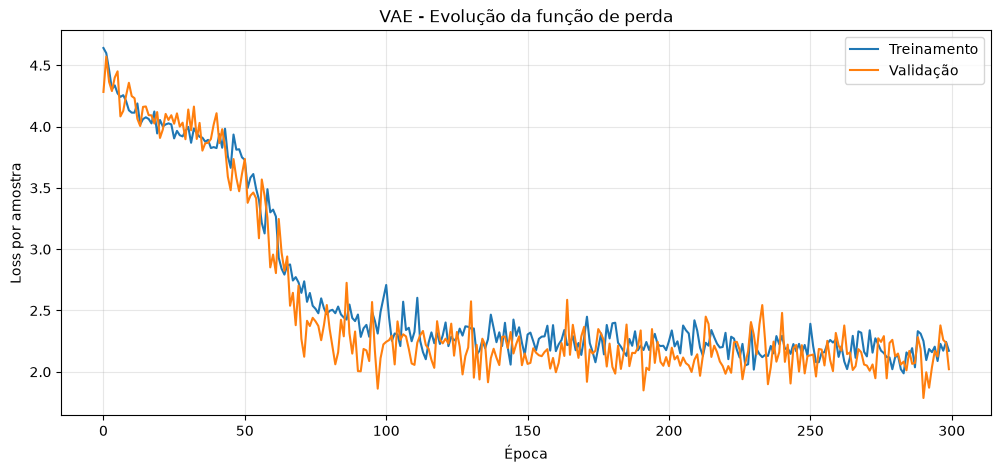

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    history["train_loss"],
    label="Treinamento"
)

plt.plot(
    history["val_loss"],
    label="Validação"
)

plt.xlabel("Época")
plt.ylabel("Loss por amostra")
plt.title("VAE - Evolução da função de perda")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

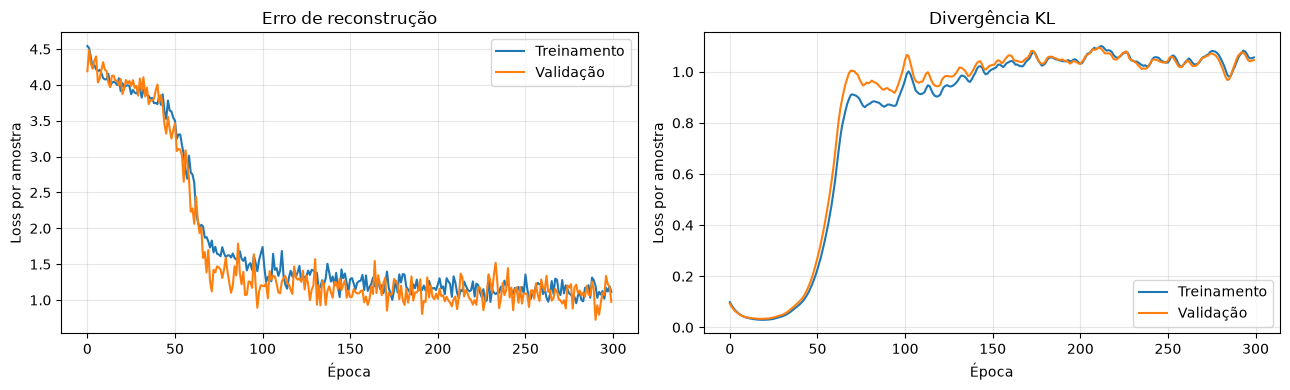

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Erro de reconstrução
axes[0].plot(
    history["train_recon"],
    label="Treinamento"
)

axes[0].plot(
    history["val_recon"],
    label="Validação"
)

axes[0].set_title("Erro de reconstrução")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss por amostra")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Divergência KL
axes[1].plot(
    history["train_kl"],
    label="Treinamento"
)

axes[1].plot(
    history["val_kl"],
    label="Validação"
)

axes[1].set_title("Divergência KL")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss por amostra")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
model.eval()

with torch.no_grad():

    mu, logvar = model.encoder(X_val_tensor.to(device))

    # Utilizando a média como representação latente
    reconstruction = model.decoder(mu)

    X_original = X_val_tensor.numpy()

    X_reconstructed = reconstruction.cpu().numpy()

In [25]:
X_original = scaler.inverse_transform(X_original)

X_reconstructed = scaler.inverse_transform(
    X_reconstructed
)

In [26]:
comparison = []

for i in range(5):

    comparison.append({
        "Tipo": f"Original {i+1}",
        **dict(zip(feature_names, X_original[i]))
    })

    comparison.append({
        "Tipo": f"Reconstruído {i+1}",
        **dict(zip(feature_names, X_reconstructed[i]))
    })

comparison_df = pd.DataFrame(comparison)

comparison_df.round(2)

,Tipo,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,Original 1,6.10,2.80,4.70,1.20
1,Reconstruído 1,5.95,2.79,4.48,1.51
2,Original 2,5.70,3.80,1.70,0.30
3,Reconstruído 2,5.19,3.52,1.75,0.35
4,Original 3,7.70,2.60,6.90,2.30
5,Reconstruído 3,7.10,3.15,6.02,2.15
6,Original 4,6.00,2.90,4.50,1.50
7,Reconstruído 4,6.03,2.82,4.60,1.57
8,Original 5,6.80,2.80,4.80,1.40
9,Reconstruído 5,6.33,2.89,5.04,1.76


In [27]:
rmse = np.sqrt(
    np.mean((X_original - X_reconstructed) ** 2)
)

print(f"RMSE das reconstruções: {rmse:.4f}")

RMSE das reconstruções: 0.2904


In [28]:
rmse_features = np.sqrt(
    np.mean(
        (X_original - X_reconstructed) ** 2,
        axis=0
    )
)

for feature, error in zip(feature_names, rmse_features):

    print(f"{feature}: {error:.4f}")

sepal length (cm): 0.2817
sepal width (cm): 0.2510
petal length (cm): 0.3806
petal width (cm): 0.2239


In [29]:
def generate_samples(model, n_samples, latent_dim, device):

    model.eval()

    with torch.no_grad():

        # Amostrando diretamente do prior
        z = torch.randn(
            n_samples,
            latent_dim,
            device=device
        )

        # Gerando novas amostras
        generated = model.decoder(z)

    return generated.cpu().numpy()

In [30]:
generated_scaled = generate_samples(
    model=model,
    n_samples=100,
    latent_dim=LATENT_DIM,
    device=device
)

generated = scaler.inverse_transform(generated_scaled)

generated_df = pd.DataFrame(
    generated,
    columns=feature_names
)

generated_df.head(10).round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.52,2.67,3.83,1.20
1,6.44,2.72,5.24,1.72
2,5.76,3.02,3.83,1.20
3,6.03,2.97,4.42,1.45
4,4.63,3.14,1.17,0.11
5,5.20,3.38,2.00,0.45
6,5.36,2.65,3.52,1.06
7,6.62,2.93,5.42,1.88
8,5.41,3.08,3.05,0.88
9,5.01,3.39,1.60,0.32


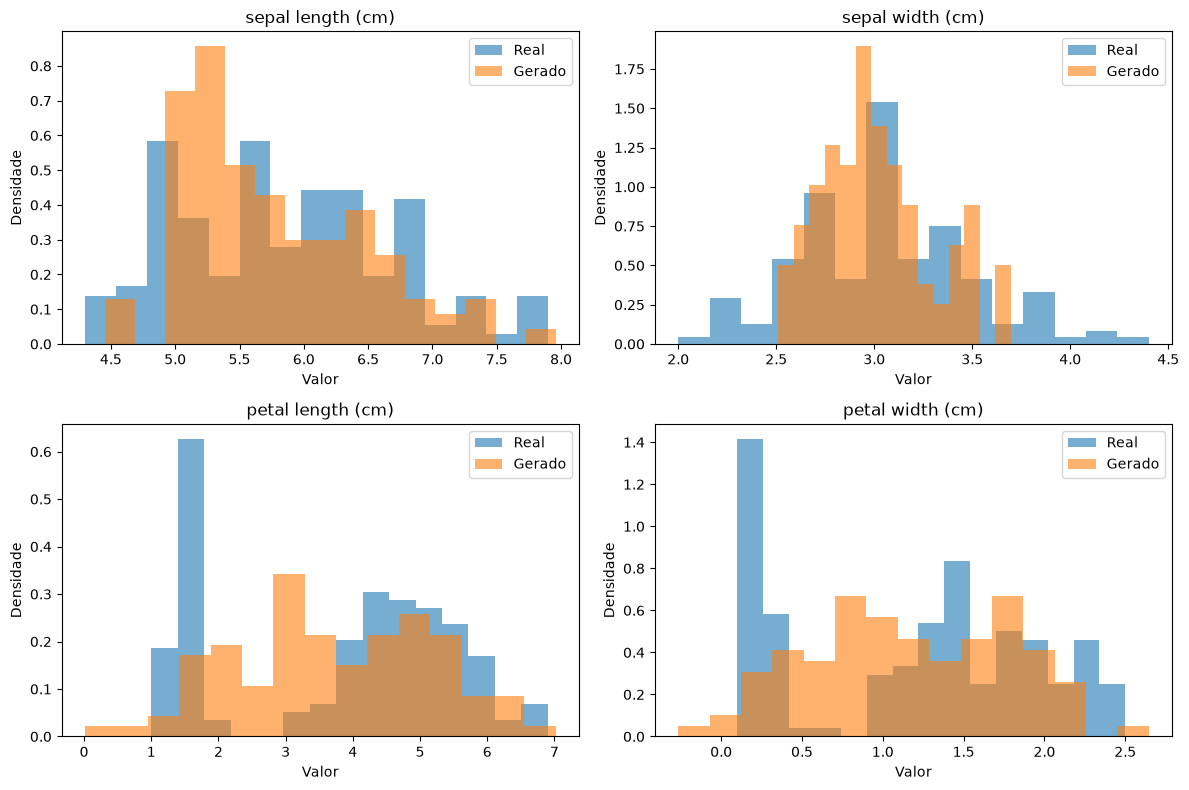

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, ax in enumerate(axes.flatten()):

    ax.hist(
        X[:, i],
        bins=15,
        alpha=0.6,
        label="Real",
        density=True
    )

    ax.hist(
        generated[:, i],
        bins=15,
        alpha=0.6,
        label="Gerado",
        density=True
    )

    ax.set_title(feature_names[i])
    ax.set_xlabel("Valor")
    ax.set_ylabel("Densidade")

    ax.legend()

plt.tight_layout()
plt.show()

In [32]:
# Transformando todo o Iris com o scaler já ajustado
X_all_scaled = scaler.transform(X)

X_all_tensor = torch.tensor(
    X_all_scaled,
    dtype=torch.float32
).to(device)

model.eval()

with torch.no_grad():

    mu, logvar = model.encoder(X_all_tensor)

    latent = mu.cpu().numpy()

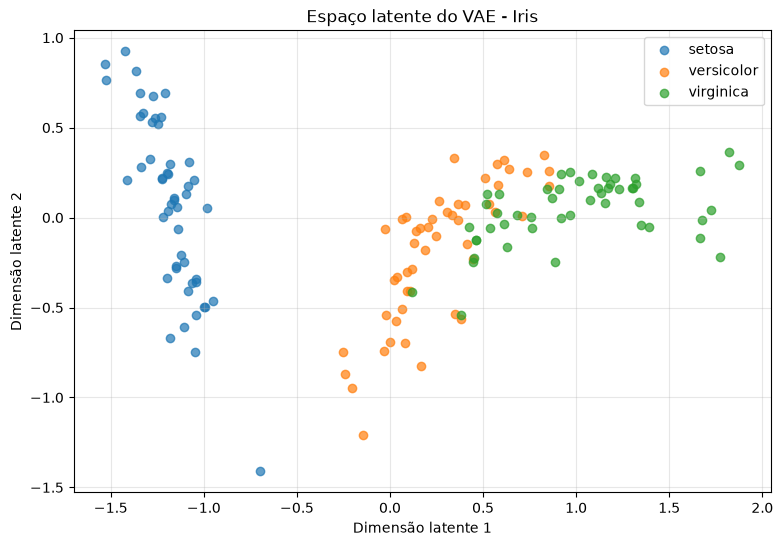

In [33]:
plt.figure(figsize=(9, 6))

for class_id, class_name in enumerate(class_names):

    mask = y == class_id

    plt.scatter(
        latent[mask, 0],
        latent[mask, 1],
        label=class_name,
        alpha=0.7
    )

plt.xlabel("Dimensão latente 1")
plt.ylabel("Dimensão latente 2")

plt.title("Espaço latente do VAE - Iris")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

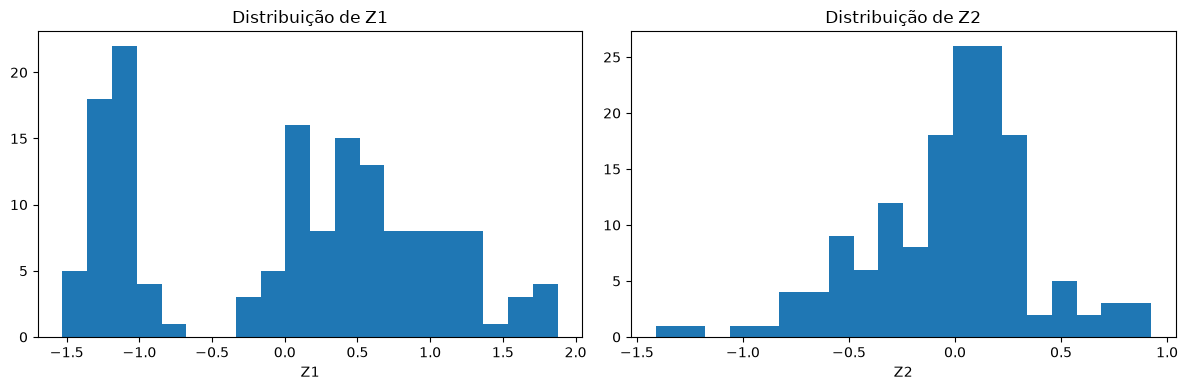

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(latent[:, 0], bins=20)
axes[0].set_title("Distribuição de Z1")
axes[0].set_xlabel("Z1")

axes[1].hist(latent[:, 1], bins=20)
axes[1].set_title("Distribuição de Z2")
axes[1].set_xlabel("Z2")

plt.tight_layout()
plt.show()

In [35]:
print("Intervalos dos dados reais:")

for i, feature in enumerate(feature_names):

    print(
        f"{feature}: "
        f"{X[:, i].min():.2f} até {X[:, i].max():.2f}"
    )

print("\nIntervalos dos dados gerados:")

for i, feature in enumerate(feature_names):

    print(
        f"{feature}: "
        f"{generated[:, i].min():.2f} até {generated[:, i].max():.2f}"
    )

Intervalos dos dados reais:
sepal length (cm): 4.30 até 7.90
sepal width (cm): 2.00 até 4.40
petal length (cm): 1.00 até 6.90
petal width (cm): 0.10 até 2.50

Intervalos dos dados gerados:
sepal length (cm): 4.46 até 7.96
sepal width (cm): 2.51 até 3.70
petal length (cm): 0.02 até 7.02
petal width (cm): -0.27 até 2.64


In [3]:
import torch

# =====================================
# 1. OBSERVAÇÃO ORIGINAL
# =====================================

x = torch.tensor([
    -0.9,
     0.8,
    -1.3,
    -1.2
])

# =====================================
# 2. SAÍDA DO ENCODER
# =====================================

mu = torch.tensor([
     0.5,
    -0.3
])

logvar = torch.tensor([
    -1.3863,
     0.0
])

# =====================================
# 3. REPARAMETERIZATION
# =====================================

std = torch.exp(0.5 * logvar)

epsilon = torch.tensor([
     0.4,
    -1.2
])

z = mu + std * epsilon

# =====================================
# 4. SAÍDA DO DECODER
# =====================================

reconstruction = torch.tensor([
    -0.7,
     0.6,
    -1.1,
    -1.0
])

# =====================================
# 5. RECONSTRUCTION LOSS
# =====================================

recon_loss = torch.sum(
    (x - reconstruction) ** 2
)

# =====================================
# 6. KL DIVERGENCE
# =====================================

kl_loss = -0.5 * torch.sum(
    1 + logvar - mu.pow(2) - logvar.exp()
)

# =====================================
# 7. LOSS FINAL
# =====================================

beta = 1.0

total_loss = recon_loss + beta * kl_loss

# =====================================
# RESULTADOS
# =====================================

print("Desvio padrão:", std)
print("Ruído:", epsilon)
print("Vetor latente:", z)
print("Reconstrução:", reconstruction)

print("\nReconstrução:", recon_loss.item())
print("KL:", kl_loss.item())
print("Loss total:", total_loss.item())

Desvio padrão: tensor([0.5000, 1.0000])
Ruído: tensor([ 0.4000, -1.2000])
Vetor latente: tensor([ 0.7000, -1.5000])
Reconstrução: tensor([-0.7000,  0.6000, -1.1000, -1.0000])

Reconstrução: 0.15999998152256012
KL: 0.4881492853164673
Loss total: 0.6481492519378662
